<a href="https://colab.research.google.com/github/tuwadmin/Analog_pH_sensor/blob/main/Copy_of_EAS308_tutorial7_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Folder in YOUR Google Drive where you saved the data files (see handout, Section 2)
path = "/content/drive/My Drive/EAS308"
!ls "{path}"

!pip install -q netCDF4 cartopy metpy

Mounted at /content/drive
goes13.2011.117.200229.BAND_01.nc  goes13.2011.117.200229.BAND_04.nc
goes13.2011.117.200229.BAND_03.nc


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_1_states_provinces_lakes.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


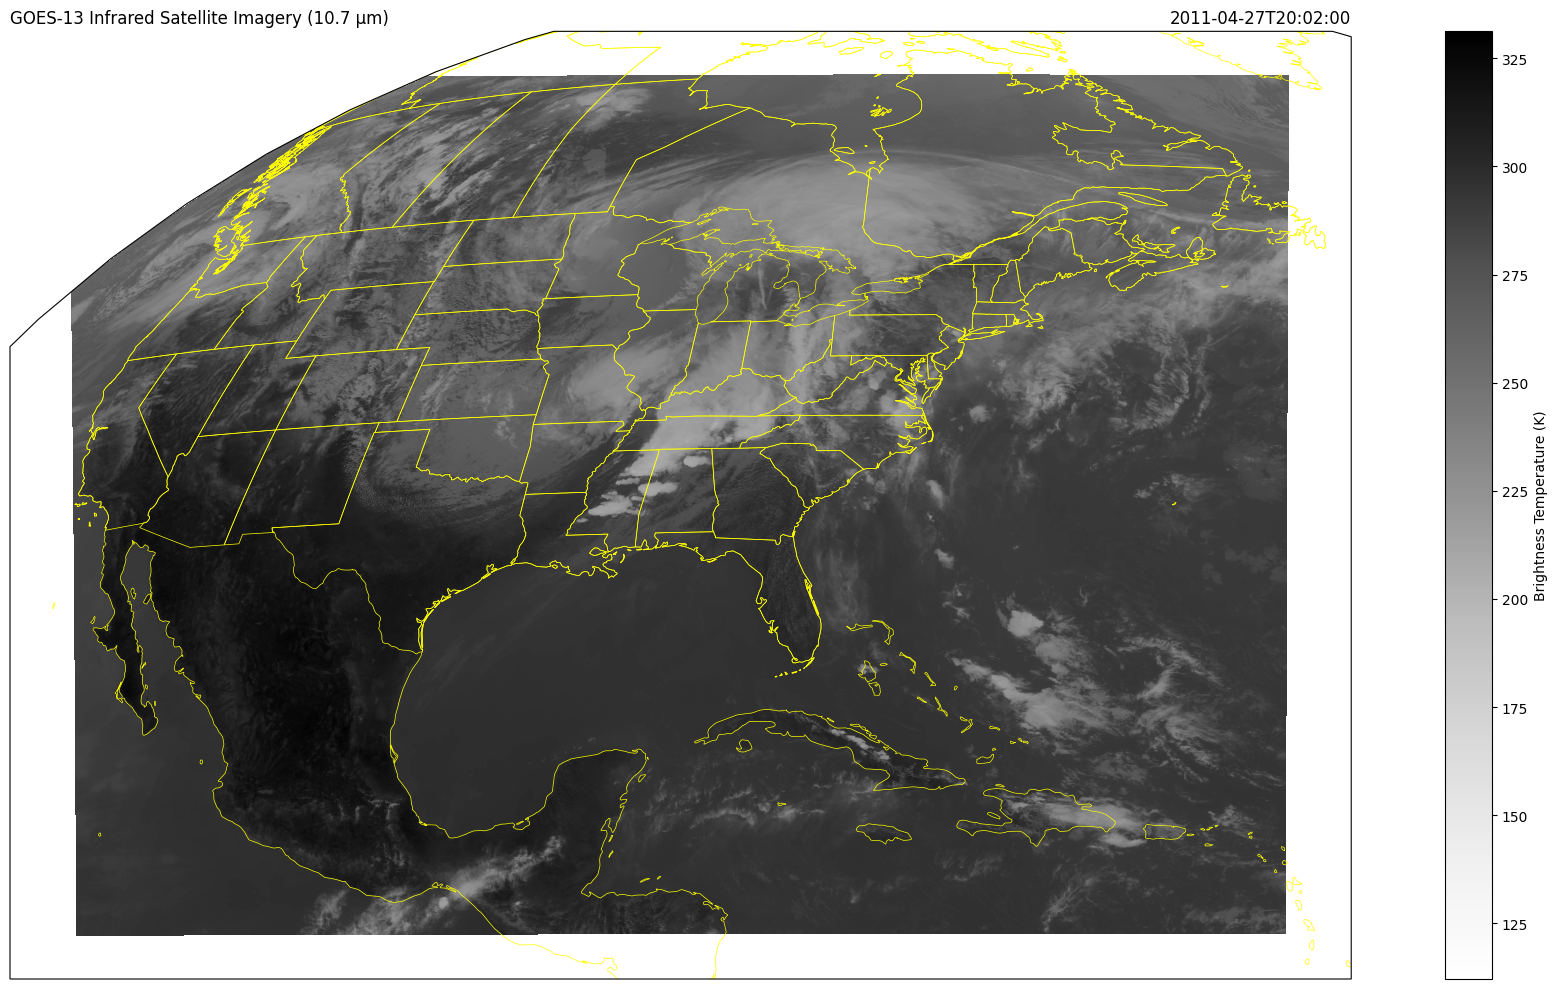

In [ ]:
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# --- Open with xarray (decodes time units to datetime) ---
file_ir = os.path.join(path, "goes13.2011.117.200229.BAND_04.nc")
ds = xr.open_dataset(file_ir, decode_times=True)

# Identify the data variable and take the first slice (often time=0)
data_var = ds["data"]
ir_16bit = data_var.isel({data_var.dims[0]: 0})

# Convert 16-bit counts to 10-bit
ir_10bit = ir_16bit / 32.0

# Mask lon/lat edges (sentinel value)
mask_val = 2.14329e9
lon = ds["lon"].where(ds["lon"] != mask_val)
lat = ds["lat"].where(ds["lat"] != mask_val)
valid = lon.notnull() & lat.notnull()
ir_10bit = ir_10bit.where(valid)

# --- Radiance calibration (step 1): counts -> scene radiance ---
# GOES-13 IR (channel 4, 10.7 um) coefficients
m_cal = 5.2285
b_cal = 15.6854
R_ir = (ir_10bit - b_cal) / m_cal
R_ir = R_ir.where(R_ir > 0)    # radiance must be positive for the log below

# --- Inverse Planck to effective temperature (step 2) ---
c1 = 1.191066e-5
c2 = 1.438833
n_ir = 937.23           # cm^-1
a_bt = -0.386043
b_bt = 1.001298

T_eff = (c2 * n_ir) / np.log(1.0 + (c1 * n_ir**3) / R_ir)
BT_ir = a_bt + b_bt * T_eff    # Brightness Temperature (K)

# Grab valid time for title
vtime = ds["time"].values[0]   # np.datetime64

# --- Plot on geostationary projection ---
mapcrs = ccrs.Geostationary(central_longitude=-75)
fig, ax = plt.subplots(figsize=(19, 10), subplot_kw={"projection": mapcrs})

# Use pcolormesh with geolocation + transform; no need to compute extent
pm = ax.pcolormesh(
    lon, lat, BT_ir,
    transform=ccrs.PlateCarree(),
    cmap="Greys",                  # cold cloud tops appear white
    shading="auto"
)
cb = fig.colorbar(pm, ax=ax, orientation="vertical", label="Brightness Temperature (K)")

# Map features
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor="yellow", linewidth=0.5)
ax.add_feature(cfeature.STATES.with_scale("50m"),    edgecolor="yellow", linewidth=0.5)

plt.title("GOES-13 Infrared Satellite Imagery (10.7 µm)", loc="left")
plt.title(np.datetime_as_string(vtime, unit="s"),           loc="right")

plt.tight_layout()
plt.show()

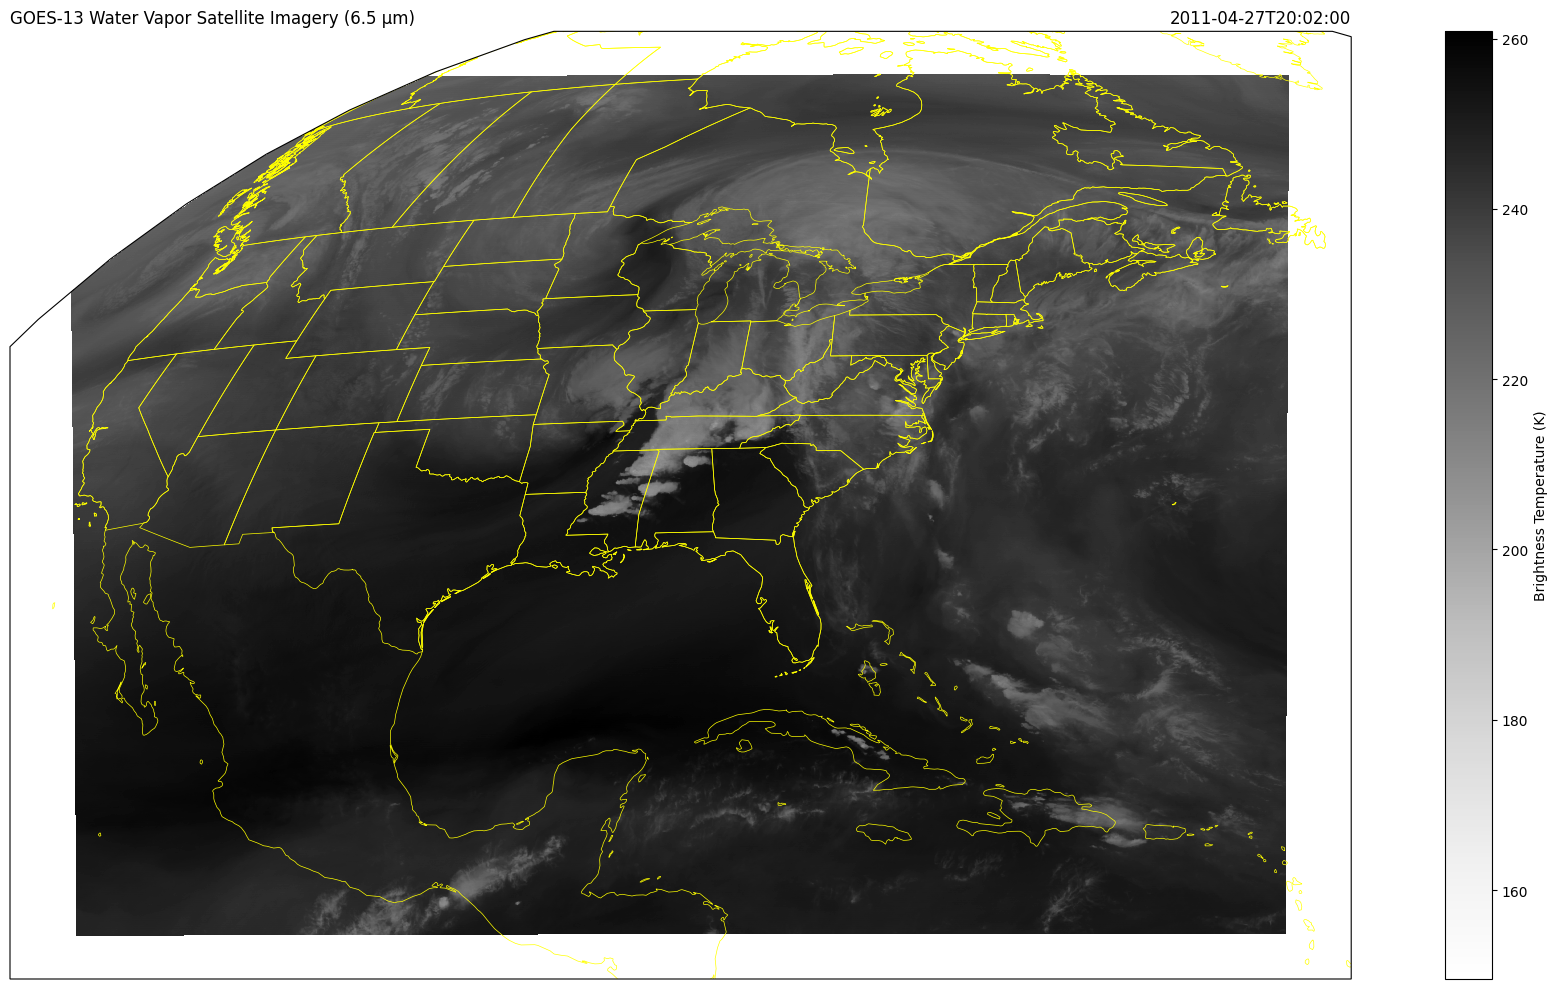

In [ ]:
# --- Open the water vapor file (channel 3, 6.5 um) ---
file_wv = os.path.join(path, "goes13.2011.117.200229.BAND_03.nc")
ds_wv = xr.open_dataset(file_wv, decode_times=True)

data_var = ds_wv["data"]
wv_16bit = data_var.isel({data_var.dims[0]: 0})

# Convert 16-bit counts to 10-bit
wv_10bit = wv_16bit / 32.0

# Mask lon/lat edges (sentinel value)
lon_wv = ds_wv["lon"].where(ds_wv["lon"] != mask_val)
lat_wv = ds_wv["lat"].where(ds_wv["lat"] != mask_val)
valid_wv = lon_wv.notnull() & lat_wv.notnull()
wv_10bit = wv_10bit.where(valid_wv)

# --- Radiance calibration (step 1): counts -> scene radiance ---
# GOES-13 water vapor (channel 3, 6.5 um) coefficients
m_wv = 38.8383
b_wv = 29.1287
R_wv = (wv_10bit - b_wv) / m_wv
R_wv = R_wv.where(R_wv > 0)

# --- Inverse Planck to effective temperature (step 2) ---
n_wv = 1522.52          # cm^-1
a_wv = -3.625663
b2_wv = 1.010018

T_eff_wv = (c2 * n_wv) / np.log(1.0 + (c1 * n_wv**3) / R_wv)
BT_wv = a_wv + b2_wv * T_eff_wv    # Brightness Temperature (K)

# --- Plot on geostationary projection ---
fig, ax = plt.subplots(figsize=(19, 10), subplot_kw={"projection": mapcrs})

pm = ax.pcolormesh(
    lon_wv, lat_wv, BT_wv,
    transform=ccrs.PlateCarree(),
    cmap="Greys",                  # moist upper levels appear white, dry areas dark
    shading="auto"
)
cb = fig.colorbar(pm, ax=ax, orientation="vertical", label="Brightness Temperature (K)")

ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor="yellow", linewidth=0.5)
ax.add_feature(cfeature.STATES.with_scale("50m"),    edgecolor="yellow", linewidth=0.5)

plt.title("GOES-13 Water Vapor Satellite Imagery (6.5 µm)", loc="left")
plt.title(np.datetime_as_string(vtime, unit="s"),               loc="right")

plt.tight_layout()
plt.show()

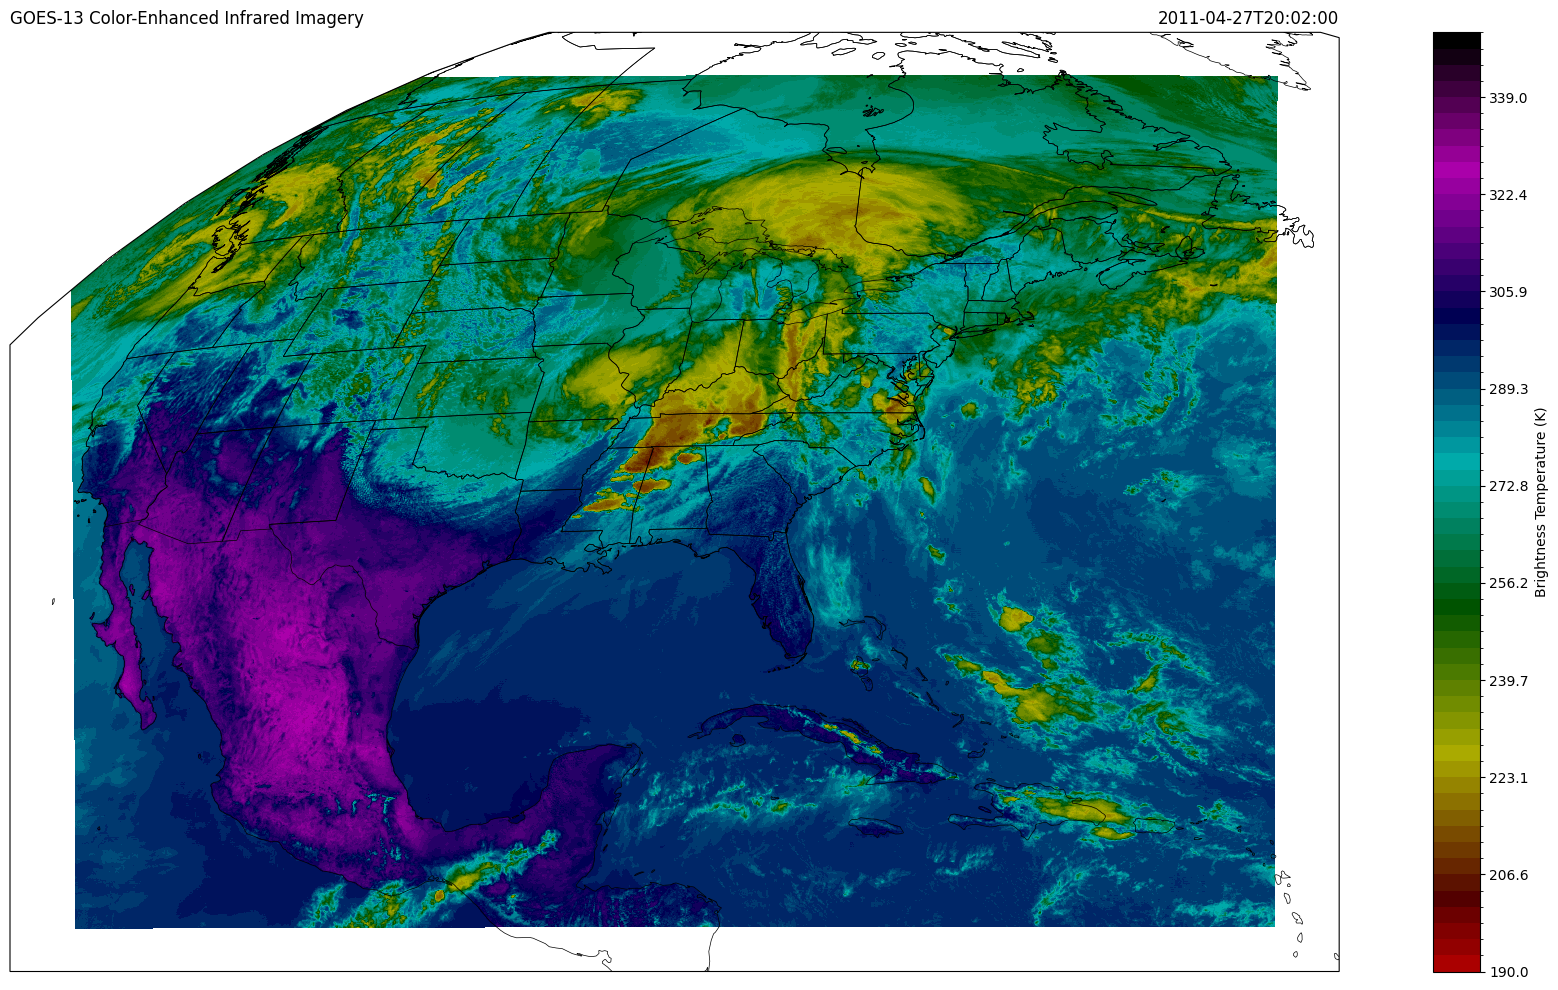

In [ ]:
# --- Color-enhanced IR image using a MetPy color table ---
from metpy.plots import colortables

# Color table name and temperature range (K)
# Other IR tables to try: "ir_bd_r", "ir_rgbv_r", "ir_tv1_r"
ir_norm, ir_cmap = colortables.get_with_range("ir_drgb_r", 190, 350)

fig, ax = plt.subplots(figsize=(19, 10), subplot_kw={"projection": mapcrs})

pm = ax.pcolormesh(
    lon, lat, BT_ir,
    transform=ccrs.PlateCarree(),
    cmap=ir_cmap, norm=ir_norm,
    shading="auto"
)
cb = fig.colorbar(pm, ax=ax, orientation="vertical", label="Brightness Temperature (K)")

ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor="black", linewidth=0.5)
ax.add_feature(cfeature.STATES.with_scale("50m"),    edgecolor="black", linewidth=0.5)

plt.title("GOES-13 Color-Enhanced Infrared Imagery", loc="left")
plt.title(np.datetime_as_string(vtime, unit="s"),   loc="right")

plt.tight_layout()
plt.show()

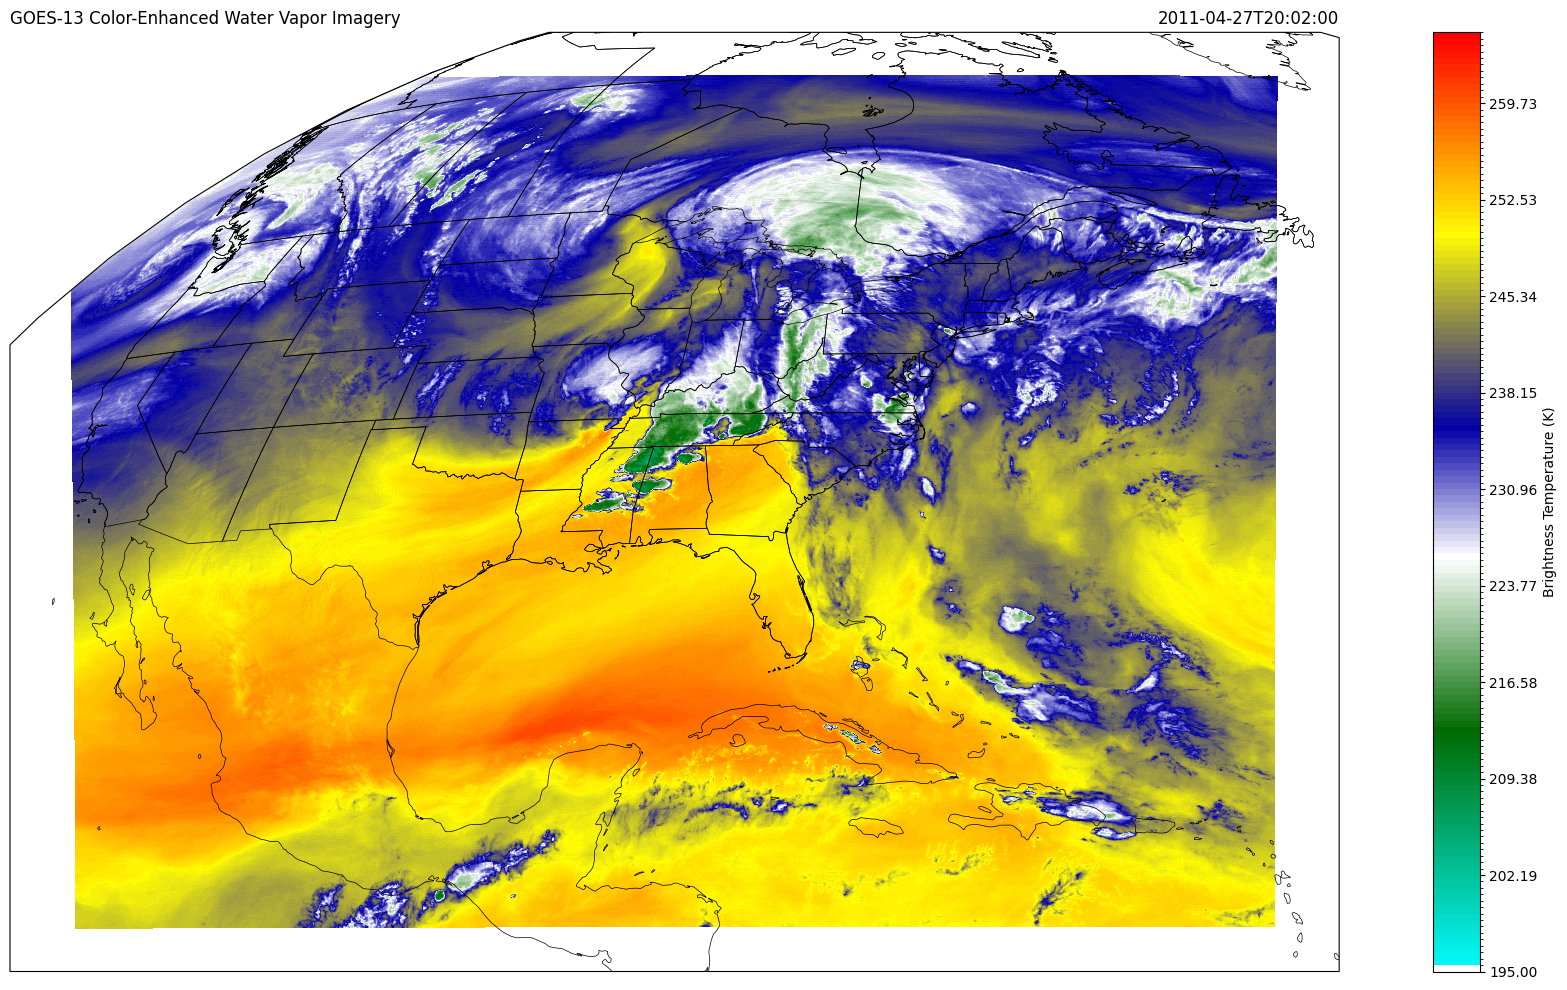

In [ ]:
# --- Color-enhanced water vapor image using a MetPy color table ---
# Other water vapor table to try: "wv_tpc_r"
wv_norm, wv_cmap = colortables.get_with_range("WVCIMSS_r", 195, 265)

fig, ax = plt.subplots(figsize=(19, 10), subplot_kw={"projection": mapcrs})

pm = ax.pcolormesh(
    lon_wv, lat_wv, BT_wv,
    transform=ccrs.PlateCarree(),
    cmap=wv_cmap, norm=wv_norm,
    shading="auto"
)
cb = fig.colorbar(pm, ax=ax, orientation="vertical", label="Brightness Temperature (K)")

ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor="black", linewidth=0.5)
ax.add_feature(cfeature.STATES.with_scale("50m"),    edgecolor="black", linewidth=0.5)

plt.title("GOES-13 Color-Enhanced Water Vapor Imagery", loc="left")
plt.title(np.datetime_as_string(vtime, unit="s"),        loc="right")

plt.tight_layout()
plt.show()